# Musanga V4 — NB01: spatially grouped, cover-stratified folds (v4_002)

**Revised pre-training protocol.** Create candidate spatial folds for a paired RGB comparison: circles + partial-crown supervision (A) versus the same plus exhaustive plots (B). Both models use identical outer-fold held-out observations; the V3.1 original 30-circle folds are retained as a separate historical analysis.

**Improvements over v4_001:** preserve the overlap graph; quantify 15/30/50 m grouping sensitivity; use **50 m primary grouping** conservatively to prevent near-neighbour units being split; balance **circle and plot counts separately**, plus within-site Musanga cover and spatial-group counts; optimize by seeded multistart local search; explicitly check split integrity and export provenance. These are *development folds*, not an untouched test set.

Stratification uses mapped **Musanga crown-cover fraction**, not field basal-area fraction. Dataset has 78 plots and 30 retained circles. Plot/circle labels may overlap; NB02 must resolve contradictory pixel labels and enforce full-chip exclusion around outer validation units. Group separation alone does not guarantee independence of image chips or forest stands.


## 00 — Load original references and audit the cover gradients

No raster reads, RGB extraction or GPU. A plot with zero intersection may still be near a circle; proximity is handled in the next section.


Mounted at /content/drive
Counts by site / type


unit_type,circle,plot
site,,
Baego,7,7
MOS,11,20
Yangambi,7,41
Yoko,5,10


Cover classes by site / type


cover_bin           0-5  5-20  20-40  40-100
site     unit_type                          
Baego    circle       2     3      1       1
         plot         2     1      2       2
MOS      circle       3     4      1       3
         plot         3     3      3      11
Yangambi circle       7     0      0       0
         plot        40     1      0       0
Yoko     circle       3     1      1       0
         plot         4     2      1       3

Percent cover summary by type


count   mean    std   min    25%    50%    75%    max
site     unit_type                                                       
Baego    circle       7.0  17.68  15.23  1.80   5.71  18.69  23.30  45.23
         plot         7.0  26.95  27.11  0.00   7.71  23.81  37.37  74.70
MOS      circle      11.0  23.53  21.68  2.18   6.53  14.85  42.05  59.08
         plot        20.0  43.72  30.73  0.00  16.54  49.71  72.48  90.38
Yangambi circle       7.0   1.38   0.62  0.61   0.78   1.79   1.84   2.02
         plot        41.0   0.98   1.35  0.00   0.00   0.15   1.88   5.13
Yoko     circle       5.0  10.01  14.33  1.56   1.82   2.96   8.55  35.13
         plot        10.0  22.05  26.85  0.00   1.03   6.09  40.77  72.82

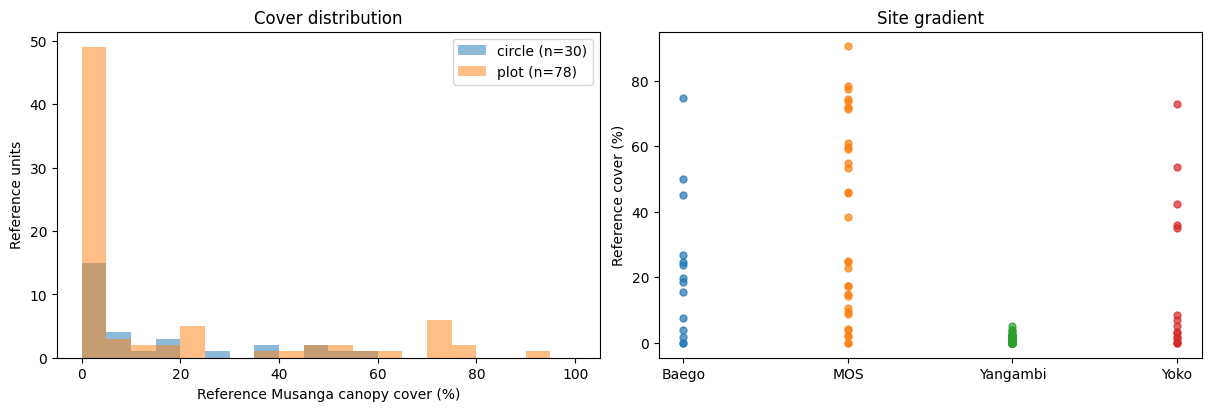

In [1]:
%pip -q install geopandas pyogrio shapely pandas numpy matplotlib
from pathlib import Path
from collections import Counter
import json
import numpy as np,pandas as pd,geopandas as gpd,matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                        Path('/content/drive/MyDrive/Musanga/Final')] if p.exists()),None)
assert ROOT is not None
REG=ROOT/'Outputs/v4/00_reference_expansion_v1/00_reference_registry_108.gpkg'
assert REG.exists(),'Run revised NB00 v4_001, Section 09 first'
g=gpd.read_file(REG).to_crs('EPSG:32635')
assert len(g)==108 and (g.unit_type=='circle').sum()==30 and (g.unit_type=='plot').sum()==78
assert g.cover_pct.between(0,100).all()
assert set(g.site)=={'Baego','MOS','Yangambi','Yoko'}
OUT=ROOT/'Outputs/v4/01_spatial_cover_folds_v1';OUT.mkdir(parents=True,exist_ok=True)
BINS=[-1e-9,5,20,40,100.000001]
LABELS=['0-5','5-20','20-40','40-100']
g['cover_bin']=pd.cut(g.cover_pct,bins=BINS,labels=LABELS,include_lowest=True,right=True).astype(str)
print('Counts by site / type');display(pd.crosstab(g.site,g.unit_type))
print('Cover classes by site / type')
display(pd.crosstab([g.site,g.unit_type],g.cover_bin).reindex(columns=LABELS,fill_value=0))
print('Percent cover summary by type')
display(g.groupby(['site','unit_type']).cover_pct.describe().round(2))
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for kind,grp in g.groupby('unit_type'):
    axs[0].hist(grp.cover_pct,bins=np.arange(0,105,5),alpha=.5,label=f'{kind} (n={len(grp)})')
axs[0].set(xlabel='Reference Musanga canopy cover (%)',ylabel='Reference units',title='Cover distribution')
axs[0].legend()
for site,grp in g.groupby('site'):
    axs[1].scatter([site]*len(grp),grp.cover_pct,alpha=.7,s=25,label=site)
axs[1].set(ylabel='Reference cover (%)',title='Site gradient')
plt.show()


## 01 — Spatial grouping and 15/30/50 m sensitivity (no raster reads)

Create connected components independently for each distance using actual polygon-to-polygon distances. **Use the 50 m grouping as the primary candidate**, unless the diagnostics show it collapses independent evaluation opportunities. This conservative choice means 15 and 30 m groupings cannot reveal additional cross-fold contacts, but the different group counts show the sensitivity of effective sample size. A 50 m polygon separation still does not guarantee independent training chips.


In [ ]:
# Spatial components: all original 108 reference polygons, including overlap chains.
from shapely.strtree import STRtree
N=len(g)
geoms=list(g.geometry)
tree=STRtree(geoms)
DISTANCES_M=[15.,30.,50.]
PRIMARY_DISTANCE_M=50.
assert PRIMARY_DISTANCE_M in DISTANCES_M
def groups_at_distance(threshold):
    parent=np.arange(N,dtype=int)
    def find(i):
        i=int(i)
        while parent[i]!=i:
            parent[i]=parent[parent[i]]
            i=int(parent[i])
        return i
    def union(i,j):
        a,b=find(i),find(j)
        if a!=b:parent[max(a,b)]=min(a,b)
    pairs=[]
    for i,geom in enumerate(geoms):
        for jraw in tree.query(geom.buffer(threshold),predicate='intersects'):
            j=int(jraw)
            if j<=i:continue
            d=float(geom.distance(geoms[j]))
            if d<=threshold+1e-7:
                assert g.site.iloc[i]==g.site.iloc[j],('Unexpected cross-site proximity',i,j)
                union(i,j)
                pairs.append((i,j,d))
    roots=[find(i) for i in range(N)]
    ids={v:k for k,v in enumerate(sorted(set(roots)))}
    groups=np.array(['SG%03d'%ids[x] for x in roots],dtype=str)
    return groups,pairs
GROUPS_BY_DISTANCE={}
PAIRS_BY_DISTANCE={}
sens=[]
for d in DISTANCES_M:
    groups,pairs=groups_at_distance(d)
    GROUPS_BY_DISTANCE[d]=groups
    PAIRS_BY_DISTANCE[d]=pairs
    temp=g[['site','unit_type','unit_id']].copy()
    temp['group']=groups
    counts=temp.groupby('group').size()
    site_groups=temp[['site','group']].drop_duplicates().groupby('site').size()
    sens.append(dict(threshold_m=d,n_groups=counts.size,
        groups_with_multiple_units=int((counts>1).sum()),
        largest_group_size=int(counts.max()),
        n_touching_or_overlapping_pairs=sum(z[2]<=1e-8 for z in pairs),
        n_positive_distance_links=sum(z[2]>1e-8 for z in pairs),
        **{'groups_'+s:int(site_groups.get(s,0)) for s in sorted(g.site.unique())}))
SENSITIVITY=pd.DataFrame(sens)
display(SENSITIVITY)
g['spatial_group']=GROUPS_BY_DISTANCE[PRIMARY_DISTANCE_M]
print('PRIMARY proximity threshold:',PRIMARY_DISTANCE_M,'m; total groups:',g.spatial_group.nunique())
display(g.groupby(['spatial_group','site']).agg(n=('unit_id','size'),
    circles=('unit_type',lambda x:int(x.eq('circle').sum())),
    plots=('unit_type',lambda x:int(x.eq('plot').sum())),
    cover_min=('cover_pct','min'),cover_max=('cover_pct','max')
).query('n>1').sort_values('n',ascending=False).round(2))
for d in DISTANCES_M:
    assert all(len(set(g.spatial_group.iloc[np.where(GROUPS_BY_DISTANCE[d]==v)[0]]))==1
               for v in set(GROUPS_BY_DISTANCE[d])),('Primary grouping breaks a closer group',d)
print('All 15/30 m components are nested in the selected 50 m components.')


## 02 — Optimize three spatial folds with explicit circle, plot, site and cover constraints

The objective balances (1) within-site reference-cover classes, (2) **circle counts and circle-cover bins**, (3) plot counts and (4) independent spatial-group counts. A large penalty disallows site-fold combinations with no circles when feasible. The randomized multistart optimizer then refines by within-site moves and swaps, without ever splitting a spatial group.

The score is a *design objective*, **not a model accuracy statistic**. Results should be inspected for scarce cover classes (e.g., Baego/Yoko high cover). Do not duplicate or synthetically manufacture held-out observations to fill empty bins.


In [ ]:
# Deterministic fold assignment; model outputs or test errors NEVER enter this optimizer.
K=3
RANDOM_SEED=20261118
LABELS=list(LABELS)
sites=sorted(g.site.unique())
site_ix={s:i for i,s in enumerate(sites)}
group_info=[]
for gid,frame in g.groupby('spatial_group',sort=True):
    assert frame.site.nunique()==1
    group_info.append(dict(
        gid=str(gid),site=str(frame.site.iloc[0]),
        n=int(len(frame)),
        n_circle=int(frame.unit_type.eq('circle').sum()),
        n_plot=int(frame.unit_type.eq('plot').sum()),
        all_bins=np.array([int(frame.cover_bin.eq(b).sum()) for b in LABELS],dtype=float),
        circle_bins=np.array([int((frame.unit_type.eq('circle')&frame.cover_bin.eq(b)).sum()) for b in LABELS],dtype=float)
    ))
all_gids=[z['gid'] for z in group_info]
by_site={s:[z for z in group_info if z['site']==s] for s in sites}
assert all(len(by_site[s])>=K for s in sites)
totals={}
for s in sites:
    zz=by_site[s]
    totals[s]=dict(
        all_bins=sum((x['all_bins'] for x in zz),np.zeros(len(LABELS))),
        circle_bins=sum((x['circle_bins'] for x in zz),np.zeros(len(LABELS))),
        circles=sum(x['n_circle'] for x in zz),
        plots=sum(x['n_plot'] for x in zz),groups=len(zz))
assert all(totals[s]['circles']>=K for s in sites),'Cannot put a circle in every site-fold.'
def objective(a):
    cost=0.
    for s in sites:
        zz=by_site[s];t=totals[s]
        allbins=np.zeros((K,len(LABELS)))
        circlebins=np.zeros_like(allbins)
        cir=np.zeros(K);plo=np.zeros(K);groups=np.zeros(K)
        for z in zz:
            f=a[z['gid']]
            allbins[f]+=z['all_bins'];circlebins[f]+=z['circle_bins']
            cir[f]+=z['n_circle'];plo[f]+=z['n_plot'];groups[f]+=1
        # Normalize each stratum to avoid dominance by common Yangambi low-cover plots.
        cost+=1.5*np.sum((allbins-t['all_bins']/K)**2/np.maximum(t['all_bins']/K,1.))
        cost+=1.6*np.sum((circlebins-t['circle_bins']/K)**2/np.maximum(t['circle_bins']/K,1.))
        cost+=2.5*np.sum((cir-t['circles']/K)**2/max(t['circles']/K,1.))
        cost+=.8*np.sum((plo-t['plots']/K)**2/max(t['plots']/K,1.))
        cost+=1.1*np.sum((groups-t['groups']/K)**2/max(t['groups']/K,1.))
        cost+=1000.*np.count_nonzero(cir<1)
        cost+=1000.*np.count_nonzero(groups<1)
    return float(cost)

# Seed each site's three folds with at least one CIRCLE-containing group, then
# allocate its remaining groups. This prevents penalized empty-circle starts.
def initialize(rng):
    a={}
    for site in sites:
        zz=by_site[site]
        circle_groups=[z for z in zz if z['n_circle']>0]
        assert len(circle_groups)>=K,('Insufficient distinct circle groups',site)
        first=list(rng.permutation(len(circle_groups)))[:K]
        for f,idx in enumerate(first):
            a[circle_groups[idx]['gid']]=f
        leftover=[z for z in zz if z['gid'] not in a]
        rng.shuffle(leftover)
        for z in leftover:
            # Place groups toward low existing site-fold group count / reference weight.
            costs=[]
            for f in range(K):
                a[z['gid']]=f
                groups=np.array([sum(a.get(q['gid'])==ff for q in zz) for ff in range(K)])
                units=np.array([sum(q['n'] for q in zz if a.get(q['gid'])==ff) for ff in range(K)])
                costs.append((groups[f],units[f],float(rng.random())))
            a[z['gid']]=min(range(K),key=lambda f:costs[f])
    assert len(a)==len(group_info)
    return a

best=None;best_score=float('inf')
N_STARTS=48
for trial in range(N_STARTS):
    rng=np.random.default_rng(RANDOM_SEED+trial)
    a=initialize(rng)
    v=objective(a)
    # Local moves and swaps retain site membership and spatial-component integrity.
    for sweep in range(7):
        improved=False
        for s in sites:
            order=list(rng.permutation(len(by_site[s])))
            for ix in order:
                z=by_site[s][ix];gid=z['gid'];old=a[gid]
                candidate_folds=list(rng.permutation(K))
                for f in candidate_folds:
                    if f==old:continue
                    a[gid]=f;w=objective(a)
                    if w<v-1e-9:
                        old=f;v=w;improved=True
                    else:a[gid]=old
            # Swap pairs only within a site (do not change unit/site attribution).
            order=list(rng.permutation(len(by_site[s])))
            for ii in order:
                zi=by_site[s][ii];gi=zi['gid']
                js=rng.choice([j for j in range(len(by_site[s])) if j!=ii],
                              size=min(4,len(by_site[s])-1),replace=False)
                for jj in js:
                    gj=by_site[s][int(jj)]['gid']
                    fi,fj=a[gi],a[gj]
                    if fi==fj:continue
                    a[gi],a[gj]=fj,fi
                    w=objective(a)
                    if w<v-1e-9:v=w;improved=True
                    else:a[gi],a[gj]=fi,fj
        if not improved:break
    if v<best_score-1e-9:best_score=v;best=a.copy()
assert best is not None
g['fold']=g.spatial_group.map(best).astype(int)
assert g.groupby('spatial_group').fold.nunique().eq(1).all()
print('Selected design objective:',round(best_score,3),'from',N_STARTS,'initializations')
print('Site × fold × reference type:')
display(pd.crosstab([g.site,g.fold],g.unit_type).reindex(columns=['circle','plot'],fill_value=0))
print('CIRCLE-ONLY cover bins per site/fold (new safeguard):')
display(pd.crosstab([g.loc[g.unit_type.eq('circle'),'site'],
                     g.loc[g.unit_type.eq('circle'),'fold']],
                    g.loc[g.unit_type.eq('circle'),'cover_bin']).reindex(columns=LABELS,fill_value=0))
print('ALL reference cover bins per site/fold:')
display(pd.crosstab([g.site,g.fold],g.cover_bin).reindex(columns=LABELS,fill_value=0))
print('Independent groups per site/fold:')
display(g[['site','fold','spatial_group']].drop_duplicates().groupby(['site','fold']).size().unstack(fill_value=0))
assert g.loc[g.unit_type.eq('circle')].groupby(['site','fold']).size().shape[0]==len(sites)*K
assert g[['site','fold','spatial_group']].drop_duplicates().groupby(['site','fold']).size().min()>=1


## 03 — Leakage screening, fold robustness, and provenance export

Check fold separation under 15/30/50 m and report per-site minimum geometric distance between **different-fold polygons**. These tests ensure geometric grouping integrity, but **NB02 must also mask/exclude all training chips whose full image footprints intersect held-out areas plus buffer**. No training, inference, or raster processing here.

All files are written to a **new v2 output directory** and preserve the executed v4_001 manifests for reproducibility.


In [ ]:
# Export candidate split and diagnostics, never overwrite original v1 artifacts.
from shapely.strtree import STRtree
import hashlib,json
assert len(g)==108 and g.spatial_group.nunique()>0
pair_rows=[]
for d in DISTANCES_M:
    pairs=PAIRS_BY_DISTANCE[d]
    violations=sum(g.fold.iloc[i]!=g.fold.iloc[j] for i,j,_ in pairs)
    pair_rows.append(dict(proximity_m=d,
        components=len(set(GROUPS_BY_DISTANCE[d])),
        tested_pairs=len(pairs),
        different_fold_pairs=int(violations),
        primary_components=g.spatial_group.nunique()))
    assert violations==0,('Spatial contact across folds',d,violations)
CONTACT=pd.DataFrame(pair_rows)
display(CONTACT)
distance_rows=[]
for site in sites:
    inds=np.flatnonzero(g.site.to_numpy()==site)
    for f in range(K):
        left=[int(i) for i in inds if g.fold.iloc[int(i)]==f]
        right=[int(i) for i in inds if g.fold.iloc[int(i)]!=f]
        assert left and right
        nearest=min(float(geoms[i].distance(geoms[j])) for i in left for j in right)
        distance_rows.append(dict(site=site,fold=f,
            minimum_polygon_distance_to_other_fold_m=nearest,
            n_heldout_units=len(left),
            n_heldout_circles=int(g.iloc[left].unit_type.eq('circle').sum()),
            n_heldout_plots=int(g.iloc[left].unit_type.eq('plot').sum())))
DISTANCE_QA=pd.DataFrame(distance_rows)
print('Within-site geometric separation between different-fold reference polygons:')
display(DISTANCE_QA.round(2))
assert DISTANCE_QA.minimum_polygon_distance_to_other_fold_m.min()>PRIMARY_DISTANCE_M-1e-6
# Count primary groups that merge when increasing threshold: already conservative 50 m.
group_sizes=g.groupby('spatial_group').size()
print('Connected groups with >1 unit:',int((group_sizes>1).sum()))
print('Historical V3.1 folds remain separate and unchanged; this is a NEW split.')

OUT2=ROOT/'Outputs/v4/01_spatial_cover_folds_v2'
OUT2.mkdir(parents=True,exist_ok=True)
g['spatial_group_distance_m']=float(PRIMARY_DISTANCE_M)
out=g[['unit_type','unit_id','site','cover_pct','cover_bin','spatial_group',
       'spatial_group_distance_m','fold','historical_fold',
       'reference_source','geometry']].copy()
out=out.sort_values(['site','spatial_group','unit_type','unit_id']).reset_index(drop=True)
p_csv=OUT2/'01_reference_groups_and_folds_v2.csv'
p_gpkg=OUT2/'01_reference_groups_and_folds_v2.gpkg'
out.drop(columns='geometry').to_csv(p_csv,index=False)
out.to_file(p_gpkg,driver='GPKG')
SENSITIVITY.to_csv(OUT2/'01_grouping_15_30_50m_sensitivity.csv',index=False)
CONTACT.to_csv(OUT2/'01_cross_fold_contact_audit.csv',index=False)
DISTANCE_QA.to_csv(OUT2/'01_cross_fold_min_distance.csv',index=False)
checksum=hashlib.sha256(p_csv.read_bytes()).hexdigest()
manifest=dict(schema='musanga_v4_01_spatial_cover_stratified_folds_v2',
  purpose='paired_rgb_circle_plus_partial_vs_circle_plus_plot_plus_partial',
  n_circles=30,n_plots=78,n_reference_units=108,
  reference_registry=str(REG),outer_folds=K,random_seed=RANDOM_SEED,
  spatial_threshold_primary_m=PRIMARY_DISTANCE_M,
  spatial_group_thresholds_audited_m=DISTANCES_M,
  stratification='within-site cover bins with separate circle and plot balance',
  reference_cover='UAV mapped crown cover; NOT field basal area',
  model_selection='nested inner training only; outer folds are development CV',
  spatial_group_integrity='no reference polygons within 50m assigned to different folds',
  training_chip_rule='NB02 must test full chip polygon against heldout polygon plus spatial buffer',
  historical_v31_folds='unchanged; use separately as historical benchmark',
  fold_objective=best_score,optimization_restarts=N_STARTS,
  output_csv=str(p_csv),csv_sha256=checksum,
  sensitivity_csv=str(OUT2/'01_grouping_15_30_50m_sensitivity.csv'),
  fold_contact_csv=str(OUT2/'01_cross_fold_contact_audit.csv'),
  distance_qa_csv=str(OUT2/'01_cross_fold_min_distance.csv'))
(OUT2/'01_reference_fold_contract_v2.json').write_text(json.dumps(manifest,indent=2))
print('FROZEN CANDIDATE:',p_csv,'SHA256:',checksum[:20])
print('NEXT: review diagnostics and adapt NB02. NO model fitting in NB01.')
